In [22]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [23]:
# Load dataset
data_url = "https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv"

df = pd.read_csv(data_url)

# Preview the dataset
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [24]:
# view the columns of the dataset
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [25]:
# view the shape of the dataset
df.shape

(20640, 10)

In [26]:
# more information about the dataset can be obtained using the `info()` method, which provides details about the data types and non-null counts for each column. Additionally, you can use the `describe()` method to get summary statistics for numerical columns.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [27]:
# 2. Separate features and target variable
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

In [28]:
# 3. Define categorical and numerical columns
cat_cols = [col for col in X.columns if X[col].dtype == "object"]
num_cols = [col for col in X.columns if X[col].dtype != "object"]

In [29]:
# 4. Build preprocessing pipelines for numeric and categorical data
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ])

In [30]:
# 5. Assemble full model pipeline with Random Forest Regressor
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

In [31]:
# 6. Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [32]:
# Define features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [33]:
# Numerical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Categorical columns
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns

print("Numerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical columns:
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype='str')

Categorical columns:
Index(['ocean_proximity'], dtype='str')


/var/folders/rm/_x9x3jkx01z158dxdwr2cs5w0000gn/T/ipykernel_91016/2786765106.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [34]:
# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [35]:
# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [36]:
# Now create your complete machine-learning pipeline:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

In [37]:
# 7. Train model
print("Training machine learning model...")

model_pipeline.fit(X_train, y_train)

# 8. Evaluate model performance
y_pred = model_pipeline.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Complete:")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R-squared Score: {r2:.4f}")

Training machine learning model...
Model Evaluation Complete:
Root Mean Squared Error: 48941.70
R-squared Score: 0.8172


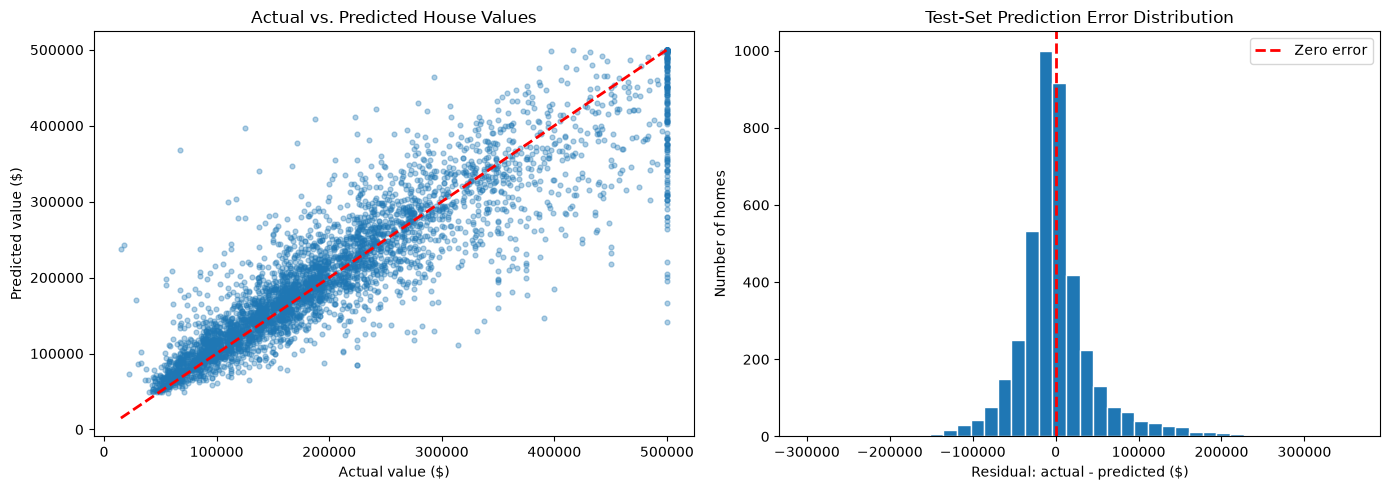

In [41]:
# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize model performance on the test set
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual values compared with predictions; the dashed line is a perfect fit.
axes[0].scatter(y_test, y_pred, alpha=0.35, s=12)
value_min = min(y_test.min(), y_pred.min())
value_max = max(y_test.max(), y_pred.max())
axes[0].plot([value_min, value_max], [value_min, value_max], "r--", linewidth=2)
axes[0].set_title("Actual vs. Predicted House Values")
axes[0].set_xlabel("Actual value ($)")
axes[0].set_ylabel("Predicted value ($)")

# Residuals centered around zero indicate little systematic prediction bias.
axes[1].hist(residuals, bins=40, edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--", linewidth=2, label="Zero error")
axes[1].set_title("Test-Set Prediction Error Distribution")
axes[1].set_xlabel("Residual: actual - predicted ($)")
axes[1].set_ylabel("Number of homes")
axes[1].legend()

fig.tight_layout()
plt.show()